# Milestone 3 — Head-to-Head Cloud Detection Benchmark (Task #4, issue #27)

Runs the **same frozen eval tiles** through all five detectors — `rgb`, `dcp`, `hot`
(classical) and `omcm`, `sam` (pretrained) — scored identically against Maxar's cloud
masks with the shared `src.eval.evaluate` (`precision / recall / f1`, cloud = mask value 2,
nodata excluded). It loads the per-method `results/<method>_tiles.csv` produced by
`scripts/run_baselines.py`, builds the precision/recall/F1 comparison table, renders
side-by-side per-method mask visualizations, and plots F1 by method and by event.

The heavy lifting (scoring every tile of all 548 scenes) is done by the batch runner;
this notebook aggregates and visualizes. It degrades gracefully if a method's CSV is
missing or a pretrained method can't run live in this environment.

## 1. Setup

In [1]:
%pip install -q numpy pandas rasterio matplotlib

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

print("Libraries imported.")

Note: you may need to restart the kernel to use updated packages.


Libraries imported.


## 2. Repository root, methods, and paths

In [2]:
def find_repo_root(start=Path.cwd()):
    """Find the repo root whether Jupyter started in the repo or in notebooks/."""
    for candidate in (start, *start.parents):
        if (candidate / "data" / "labeled_scenes.csv").is_file() and (
            candidate / "scripts" / "run_baselines.py"
        ).is_file():
            return candidate
    raise FileNotFoundError(
        "Could not find the repository root. Start Jupyter in the repo or a subfolder."
    )

ROOT = find_repo_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

DATA = ROOT / "data"
RESULTS = ROOT / "results"
FIGURES = RESULTS / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

# Method order + display labels (classical first, then pretrained).
METHODS = ["rgb", "dcp", "hot", "omcm", "sam"]
LABELS = {"rgb": "RGB", "dcp": "DCP", "hot": "HOT",
          "omcm": "OmniCloudMask", "sam": "SAM (zero-shot)"}

labeled_scenes = pd.read_csv(DATA / "labeled_scenes.csv")
print(f"Repository: {ROOT}")
print(f"Labeled scenes: {len(labeled_scenes)}  across {labeled_scenes['event'].nunique()} events")

Repository: /Users/rushildileep/Documents/Ursa-Space-Systems-1B-cloud-detection-in-very-high-resolution-optical-satellite-imagery
Labeled scenes: 548  across 8 events


## 3. Load each method's per-tile scores

`scripts/run_baselines.py --method <m>` writes one row per `(scene, tile)` to
`results/<method>_tiles.csv` with columns
`method, event, item_id, tile_row, tile_col, n_valid, cloud_frac, precision, recall, f1`.
Scenes that failed (e.g. the ~10 single-band South-Africa captures, or a missing `-ms`
product for OMCM) are logged as rows with an `error` column instead of scores.

In [3]:
per_tile = {}        # method -> scored-tile DataFrame
missing, fail_counts = [], {}

for m in METHODS:
    path = RESULTS / f"{m}_tiles.csv"
    if not path.is_file():
        missing.append(m)
        continue
    df = pd.read_csv(path)
    n_err = int(df["error"].notna().sum()) if "error" in df.columns else 0
    scored = df[df["f1"].notna()] if "f1" in df.columns else df.iloc[0:0]
    per_tile[m] = scored
    fail_counts[m] = n_err
    print(f"{LABELS[m]:16} scored tiles: {len(scored):6d}   failed-scene rows: {n_err}")

if missing:
    print("\nNot run yet (CSV missing):", ", ".join(LABELS[m] for m in missing))
    print("Run:  python scripts/run_baselines.py --method " + " / ".join(missing))

available = [m for m in METHODS if m in per_tile and len(per_tile[m])]

RGB              scored tiles:  10072   failed-scene rows: 10
DCP              scored tiles:  10072   failed-scene rows: 10
HOT              scored tiles:  10072   failed-scene rows: 10
OmniCloudMask    scored tiles:  10072   failed-scene rows: 10
SAM (zero-shot)  scored tiles:    431   failed-scene rows: 2


## 4. Comparison table — precision / recall / F1

`results/summary_by_event.csv` is the authoritative head-to-head table and the table
below loads it directly: `rgb/dcp/hot/omcm` come from the full 548-scene run, and the
**SAM row comes from the SAM task owner's run (issue #26)**, which uses a finer grid than
the quick local reproduction this notebook runs in Section 6. (The identical format — mean
P/R/F1 per `(method, event)` plus an `ALL` row per method — is what `run_baselines.write_summary`
produces; it is regenerated by the batch runs, not overwritten here.)

In [4]:
summary = pd.read_csv(RESULTS / "summary_by_event.csv")
present = [m for m in METHODS if m in set(summary["method"])]

# Overall head-to-head (ALL rows), ordered by METHODS, ranked by F1.
overall = (summary[summary["event"] == "ALL"]
           .set_index("method").reindex(present))
print("Overall (all events) — ranked by F1:")
display(overall[["precision", "recall", "f1"]].sort_values("f1", ascending=False))

# Per-event F1 table (methods as columns).
f1_pivot = (summary[summary["event"] != "ALL"]
            .pivot(index="event", columns="method", values="f1")
            .reindex(columns=present))
print("\nF1 by event:")
display(f1_pivot.round(3))

Overall (all events) — ranked by F1:


,precision,recall,f1
method,,,
omcm,0.7987,0.8341,0.8017
rgb,0.8018,0.5215,0.5936
hot,0.5025,0.8730,0.5804
dcp,0.8468,0.3792,0.4840
sam,0.7038,0.4208,0.4592



F1 by event:


method,rgb,dcp,hot,omcm,sam
event,,,,,
Cyclone-Chido-Dec15,0.673,0.536,0.594,0.931,0.553
Hurricane-Maria-PuertoRico-Oct-2017,0.505,0.482,0.456,0.718,0.362
HurricaneHelene-Oct24,0.500,0.368,0.462,0.779,0.340
HurricaneMilton-Oct24,0.441,0.464,0.629,0.659,0.374
cyclone-emnati22,0.625,0.509,0.548,0.799,0.479
ghana-explosion22,0.695,0.517,0.463,0.825,0.558
southafrica-flooding22,0.333,0.281,0.636,0.740,0.180
tonga-volcano21,0.623,0.494,0.642,0.848,0.489


## 5. Identical-tile check

Every method is scored on tiles derived deterministically from `labeled_scenes.csv`
(`iter_tiles`, `tile=512`), and Task #1 froze that exact grid in `data/eval_tiles.csv`.
Here we confirm the methods share the same tile keys and measure coverage against the
frozen manifest.

In [5]:
KEY = ["event", "item_id", "tile_row", "tile_col"]
frozen = pd.read_csv(DATA / "eval_tiles.csv")
frozen_keys = set(map(tuple, frozen[KEY].itertuples(index=False, name=None)))
print(f"Frozen manifest tiles: {len(frozen_keys)}")

key_sets = {m: set(map(tuple, df[KEY].itertuples(index=False, name=None)))
            for m, df in per_tile.items() if len(df)}
for m, ks in key_sets.items():
    cov = 100 * len(ks & frozen_keys) / len(frozen_keys) if frozen_keys else 0
    print(f"{LABELS[m]:16} {len(ks):6d} tiles   coverage of frozen set: {cov:5.1f}%")

if len(key_sets) > 1:
    shared = set.intersection(*key_sets.values())
    print(f"\nTiles scored by ALL available methods (strict head-to-head set): {len(shared)}")

Frozen manifest tiles: 10072
RGB               10072 tiles   coverage of frozen set: 100.0%
DCP               10072 tiles   coverage of frozen set: 100.0%
HOT               10072 tiles   coverage of frozen set: 100.0%
OmniCloudMask     10072 tiles   coverage of frozen set: 100.0%
SAM (zero-shot)     431 tiles   coverage of frozen set:   4.3%

Tiles scored by ALL available methods (strict head-to-head set): 431


## 6. Side-by-side mask visualizations

For a small curated showcase (kept tiny so pretrained methods stay cheap to run live),
run each detector on the tile and lay out `[RGB | Ground truth | <each method>]` with
P/R/F1 in the titles. Classical methods run instantly; OMCM is scene-level (predict the
`-ms` scene once, slice the tile); SAM needs a checkpoint + `segment_anything` — any
method that can't run here shows an "unavailable" panel instead of failing the cell.

Note: the SAM panel here is this notebook's quick local reproduction (coarse grid), which
is weaker than the SAM task owner's run that feeds the headline table in Section 4.

In [6]:
import os

from src.tiling import read_scene, iter_tiles
from src.eval import evaluate
from src.methods.registry import get_detector

# A few scenes spanning events / failure modes. Edit freely; keep it short.
SHOWCASE_ITEM_IDS = [
    "38/211311112122/104001009990E600",      # Cyclone-Chido
    "19/122002311232/105001000B8E2F00",      # Hurricane-Maria
]
MAX_TILES = 3            # total tiles rendered (bounds SAM/OMCM live cost)
SAM_POINTS = "16"        # coarse grid = faster SAM if it runs live
os.environ.setdefault("SAM_POINTS_PER_SIDE", SAM_POINTS)

def stretch(rgb):
    """Per-band 2-98 percentile stretch for display only (mirrors preview_rgb_threshold)."""
    out = rgb.astype(np.float32)
    for i in range(out.shape[-1]):
        p2, p98 = np.percentile(out[..., i], (2, 98))
        out[..., i] = np.clip((out[..., i] - p2) / (p98 - p2 + 1e-9), 0, 1)
    return out

# Resolve detectors once; a method that can't be built is simply skipped in the grid.
detectors = {}
for m in METHODS:
    try:
        detectors[m] = get_detector(m)
    except Exception as e:
        print(f"{LABELS[m]}: detector unavailable ({e})")

def predict_tile(m, img_tile, scene_pred, r0, c0):
    """Return a (h, w) uint8 mask for method m on this tile, or None if it can't run."""
    fn = detectors.get(m)
    if fn is None:
        return None
    try:
        if getattr(fn, "scene_level", False):
            if scene_pred is None:
                return None
            h, w = img_tile.shape[:2]
            return scene_pred[r0:r0 + h, c0:c0 + w]
        return fn(img_tile)
    except Exception as e:
        print(f"  {LABELS[m]} failed on tile: {e}")
        return None

/Users/rushildileep/Documents/Ursa-Space-Systems-1B-cloud-detection-in-very-high-resolution-optical-satellite-imagery/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [7]:
# Collect showcase tiles (first scored tile per scene that has both cloud and clear).
examples = []
for item_id in SHOWCASE_ITEM_IDS:
    if len(examples) >= MAX_TILES:
        break
    row = labeled_scenes[labeled_scenes["item_id"].astype(str) == item_id]
    if row.empty:
        continue
    row = row.iloc[0]
    image, mask, _ = read_scene(row["visual_href"], row["mask_href"])

    # OMCM predicts the whole -ms scene once; slice per tile below.
    scene_pred = None
    omcm = detectors.get("omcm")
    if omcm is not None and getattr(omcm, "scene_level", False):
        try:
            ms_href = str(row["visual_href"]).replace("-visual.tif", "-ms.tif")
            scene_pred = omcm.detect_scene(ms_href, out_hw=mask.shape)
        except Exception as e:
            print(f"OMCM scene predict failed for {item_id}: {e}")

    for tr, tc, r0, c0, img_tile, mask_tile in iter_tiles(image, mask, 512):
        valid = mask_tile != 0
        truth = mask_tile == 2
        if not valid.any() or truth[valid].mean() in (0.0, 1.0):
            continue  # want a mix of cloud and clear for an informative panel
        preds = {}
        for m in METHODS:
            p = predict_tile(m, img_tile, scene_pred, r0, c0)
            if p is not None:
                preds[m] = (p, evaluate(p, truth, valid))
        examples.append({"event": row["event"], "item_id": item_id,
                         "img": img_tile, "truth": truth, "preds": preds})
        break
    if len(examples) >= MAX_TILES:
        break

print(f"Collected {len(examples)} showcase tiles; methods shown: "
      + ", ".join(LABELS[m] for m in METHODS if any(m in e['preds'] for e in examples)))

/Users/rushildileep/Documents/Ursa-Space-Systems-1B-cloud-detection-in-very-high-resolution-optical-satellite-imagery/.venv/lib/python3.13/site-packages/omnicloudmask/cloud_mask.py:456: UserWarning: Significant no-data areas detected. Adjusting patch size to 265px and overlap to 132px to minimize no-data patches.
  patch_overlap, patch_size = check_patch_size(


/Users/rushildileep/Documents/Ursa-Space-Systems-1B-cloud-detection-in-very-high-resolution-optical-satellite-imagery/.venv/lib/python3.13/site-packages/omnicloudmask/cloud_mask.py:456: UserWarning: Significant no-data areas detected. Adjusting patch size to 265px and overlap to 132px to minimize no-data patches.
  patch_overlap, patch_size = check_patch_size(


Collected 2 showcase tiles; methods shown: RGB, DCP, HOT, OmniCloudMask, SAM (zero-shot)


saved /Users/rushildileep/Documents/Ursa-Space-Systems-1B-cloud-detection-in-very-high-resolution-optical-satellite-imagery/results/figures/benchmark_examples.png


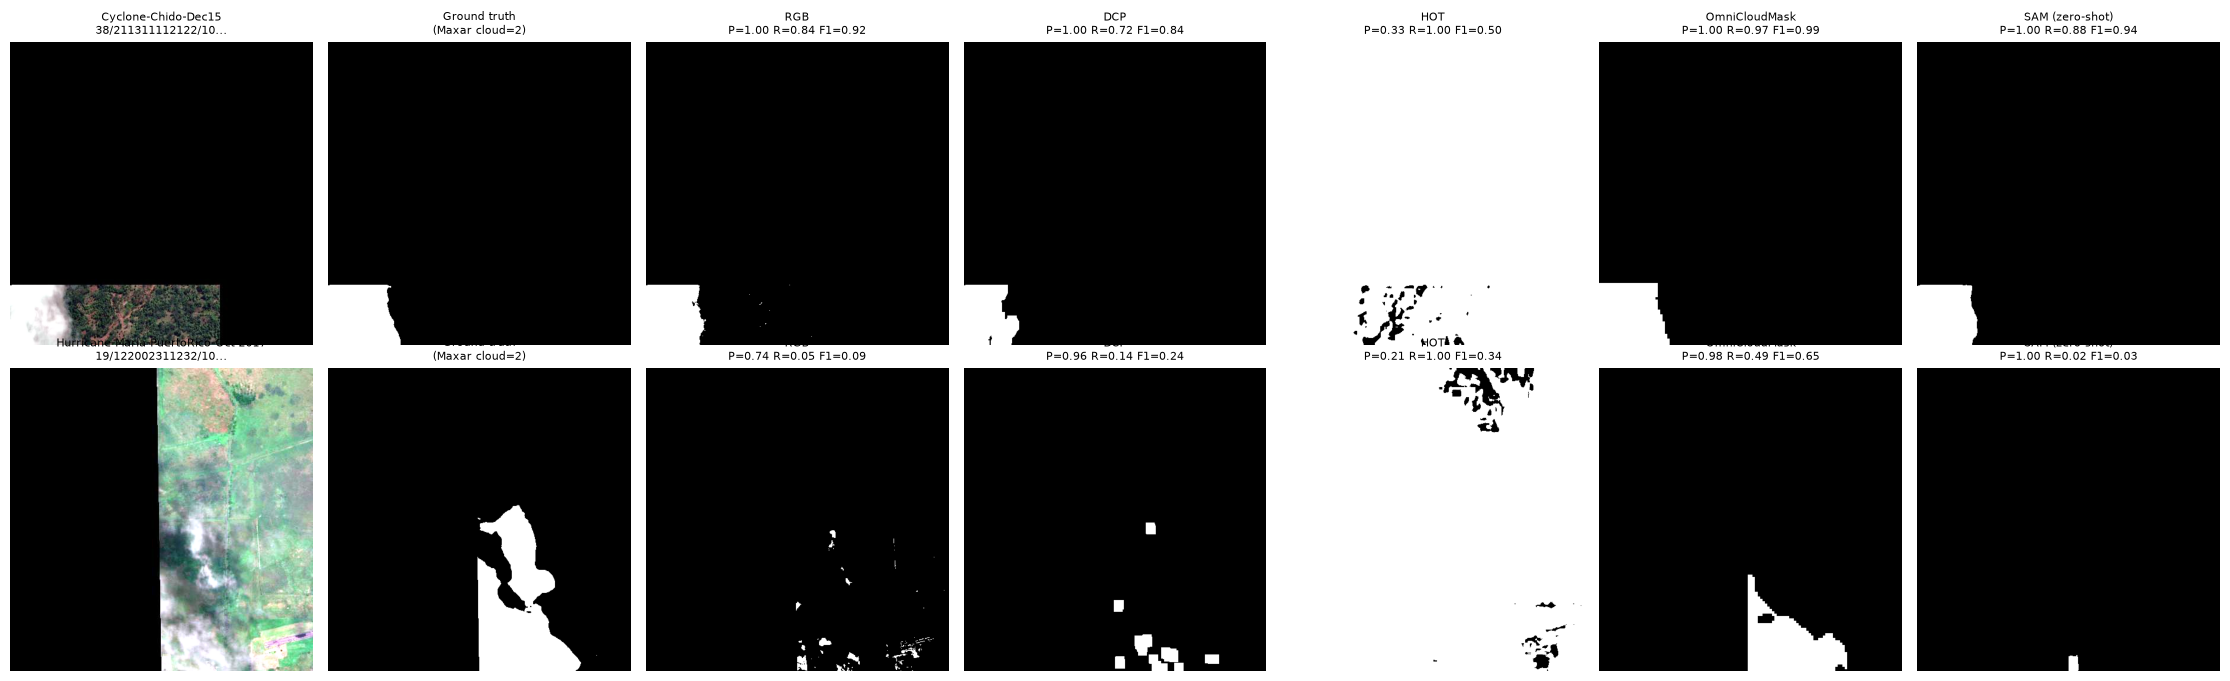

In [8]:
shown = [m for m in METHODS if any(m in e["preds"] for e in examples)]
ncols = 2 + len(shown)                      # RGB + GT + one per method
nrows = max(1, len(examples))
fig, axes = plt.subplots(nrows, ncols, figsize=(3.2 * ncols, 3.4 * nrows))
axes = np.atleast_2d(axes)

for i, ex in enumerate(examples):
    axes[i, 0].imshow(stretch(ex["img"]))
    axes[i, 0].set_title(f"{ex['event']}\n{ex['item_id'][:18]}...", fontsize=8)
    axes[i, 1].imshow(ex["truth"], cmap="gray")
    axes[i, 1].set_title("Ground truth\n(Maxar cloud=2)", fontsize=8)
    for j, m in enumerate(shown, start=2):
        ax = axes[i, j]
        if m in ex["preds"]:
            pred, sc = ex["preds"][m]
            ax.imshow(pred, cmap="gray")
            ax.set_title(f"{LABELS[m]}\nP={sc['precision']:.2f} R={sc['recall']:.2f}"
                         f" F1={sc['f1']:.2f}", fontsize=8)
        else:
            ax.text(0.5, 0.5, f"{LABELS[m]}\nunavailable", ha="center", va="center",
                    fontsize=9); ax.set_facecolor("#f0f0f0")
    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
fig.savefig(FIGURES / "benchmark_examples.png", dpi=110, bbox_inches="tight")
print(f"saved {FIGURES / 'benchmark_examples.png'}")
plt.show()

## 7. Comparison figures — F1 by method and by event

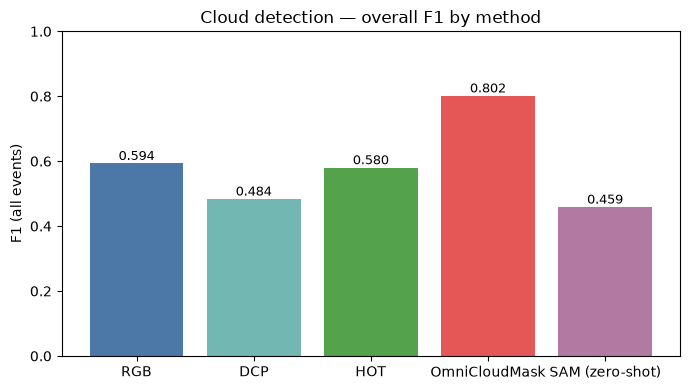

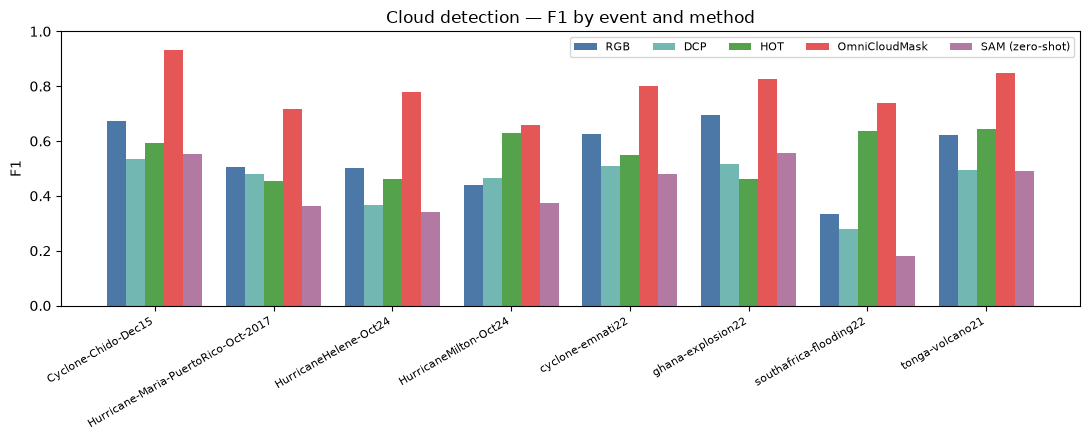

In [9]:
order = present
colors = {"rgb": "#4C78A8", "dcp": "#72B7B2", "hot": "#54A24B",
          "omcm": "#E45756", "sam": "#B279A2"}

# Overall F1 per method.
fig, ax = plt.subplots(figsize=(7, 4))
vals = overall.loc[order, "f1"]
ax.bar([LABELS[m] for m in order], vals, color=[colors[m] for m in order])
for i, v in enumerate(vals):
    ax.text(i, v + 0.01, f"{v:.3f}", ha="center", fontsize=9)
ax.set_ylabel("F1 (all events)"); ax.set_ylim(0, 1)
ax.set_title("Cloud detection — overall F1 by method")
plt.tight_layout(); fig.savefig(FIGURES / "f1_by_method.png", dpi=110, bbox_inches="tight")
plt.show()

# Grouped F1 by event.
ev = f1_pivot.reindex(columns=order)
fig, ax = plt.subplots(figsize=(11, 4.5))
x = np.arange(len(ev.index)); w = 0.8 / max(1, len(order))
for k, m in enumerate(order):
    ax.bar(x + k * w, ev[m].values, w, label=LABELS[m], color=colors[m])
ax.set_xticks(x + 0.4 - w / 2); ax.set_xticklabels(ev.index, rotation=30, ha="right", fontsize=8)
ax.set_ylabel("F1"); ax.set_ylim(0, 1); ax.legend(fontsize=8, ncol=len(order))
ax.set_title("Cloud detection — F1 by event and method")
plt.tight_layout(); fig.savefig(FIGURES / "f1_by_event.png", dpi=110, bbox_inches="tight")
plt.show()

## 8. Summary — which method wins where

In [10]:
rank = overall["f1"].sort_values(ascending=False)
print("Overall F1 ranking:")
for m, v in rank.items():
    print(f"  {LABELS[m]:16} F1={v:.3f}  (P={overall.loc[m,'precision']:.3f}"
          f", R={overall.loc[m,'recall']:.3f})")

print("\nBest method per event:")
for event in f1_pivot.index:
    rowvals = f1_pivot.loc[event].dropna()
    if len(rowvals):
        best = rowvals.idxmax()
        print(f"  {event:28} {LABELS[best]:16} F1={rowvals.max():.3f}")

Overall F1 ranking:
  OmniCloudMask    F1=0.802  (P=0.799, R=0.834)
  RGB              F1=0.594  (P=0.802, R=0.521)
  HOT              F1=0.580  (P=0.502, R=0.873)
  DCP              F1=0.484  (P=0.847, R=0.379)
  SAM (zero-shot)  F1=0.459  (P=0.704, R=0.421)

Best method per event:
  Cyclone-Chido-Dec15          OmniCloudMask    F1=0.931
  Hurricane-Maria-PuertoRico-Oct-2017 OmniCloudMask    F1=0.718
  HurricaneHelene-Oct24        OmniCloudMask    F1=0.779
  HurricaneMilton-Oct24        OmniCloudMask    F1=0.659
  cyclone-emnati22             OmniCloudMask    F1=0.799
  ghana-explosion22            OmniCloudMask    F1=0.825
  southafrica-flooding22       OmniCloudMask    F1=0.740
  tonga-volcano21              OmniCloudMask    F1=0.848


## Interpretation and limitations

- **Scores are agreement with Maxar's cloud model**, not hand-labeled truth. Shadow
  (mask value 3) is scored as not-cloud; nodata (0) is excluded.
- **OMCM uses Red/Green/NIR** from the `-ms` product, so it is not a strictly-RGB entry —
  it has spectral information the classical/SAM RGB methods do not.
- **SAM is zero-shot**: a generic segmenter plus a trivial brightness/saturation cloud
  rule, deliberately the simplest cue. It was run with `SAM_MODEL_TYPE`/`SAM_POINTS_PER_SIDE`
  recorded in `docs/06`; a coarser grid trades recall for speed on CPU.
- Classical baselines show the known precision/recall trade-off (RGB & DCP conservative =
  high precision / low recall; HOT loose = high recall / low precision).
- Failure modes to inspect in Task #5: smoke vs cloud, bright surfaces (snow, sand,
  rooftops) read as cloud, and thin/diffuse cloud.